Folie 27: Hausaufgabe

In [2]:
import pandas as pd
forest_fires = pd.read_excel(pd.ExcelFile("C:\\0 Eigene Dateien\\9 Lehre\\2019 Einführung in Data Science\\4. Veranstaltung\\Waldbrände.xlsx"))
forest_fires_filtered=forest_fires.drop([0], axis=0)
forest_fires_filtered.replace(["Janeiro", "Fevereiro", "Março", "Abril","Maio","Junho", "Julho","Agosto","Setembro","Outubro","Novembro","Dezembro"], [1, 2, 3,4,5,6,7,8,9,10,11,12], inplace = True)
forest_fires_filtered.rename(columns={"number.1": "absolute"}, inplace = True)
forest_fires_grouped = forest_fires_filtered.groupby(["state","month"], as_index = False).sum()
forest_fires_grouped["absolute"]=(forest_fires_grouped["absolute"]/forest_fires_grouped["absolute"].sum())
forest_fires_probs=pd.DataFrame(forest_fires_grouped[["state","month","absolute"]])
import seaborn as sns
cm = sns.diverging_palette(120, 10, as_cmap=True)
s = forest_fires_probs.style.background_gradient(cmap=cm)
s

,state,month,absolute
0,Acre,1,0.000234
1,Acre,2,0.000111
2,Acre,3,0.000135
3,Acre,4,0.000240
4,Acre,5,0.000474
5,Acre,6,0.001504
6,Acre,7,0.013432
7,Acre,8,0.367270
8,Acre,9,0.547211
9,Acre,10,0.051207


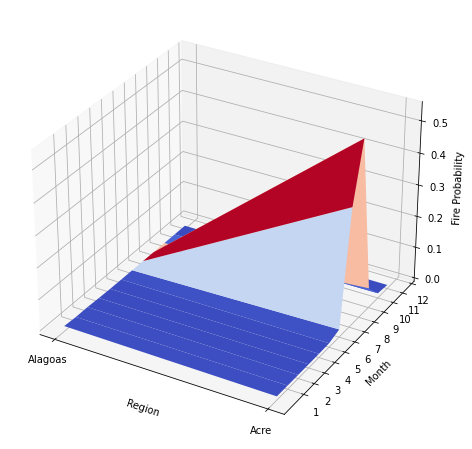

In [5]:
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
acre = forest_fires_probs[forest_fires_probs["state"]=="Acre"]
alagoas =forest_fires_probs[forest_fires_probs["state"]=="Alagoas"]
x, y = np.meshgrid(np.arange(2), np.arange(12))
alagoas = pd.Series(alagoas["absolute"].to_numpy(), index = [0,1,2,3,4,5,6,7])
acre = pd.Series(acre["absolute"])
result_series = pd.concat([alagoas,acre], axis = 1).fillna(0)

z = result_series.to_numpy()

plt.rcParams["figure.figsize"] = (10,8)
axes = plt.axes(projection='3d')
axes.plot_surface(x, y, z, cmap=cm.coolwarm)


axes.set_xlabel('Region')
plt.xticks([0,1],["Alagoas","Acre"])
axes.set_ylabel('Month')
plt.yticks(np.arange(1,13))
axes.set_zlabel('Fire Probability')
axes.set_zlim3d(bottom=0)

plt.show()

Folie 45: Häufigkeitsverteilung

In [6]:
import numpy as np
import pandas as pd
n = 50
#rents = np.random.randint(50,600,n)
rents = np.random.normal(300,75,n)
intervals = np.linspace(0, 600, 7)
rents_bins = pd.cut(rents,intervals,right=True)
df = pd.DataFrame(pd.value_counts(rents_bins), columns =["absolute"])
df["relative"] = df["absolute"]/len(rents)
df.sort_index(inplace = True)
df

,absolute,relative
"(0.0, 100.0]",0,0.00
"(100.0, 200.0]",8,0.16
"(200.0, 300.0]",18,0.36
"(300.0, 400.0]",17,0.34
"(400.0, 500.0]",6,0.12
"(500.0, 600.0]",1,0.02


Folie 47: Darstellung Häufigkeitsverteilung

<AxesSubplot:>

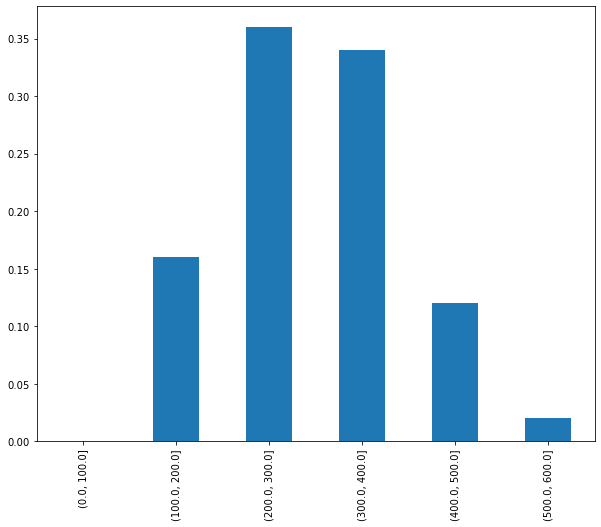

In [7]:
df["relative"].plot.bar()

array([<AxesSubplot:ylabel='absolute'>, <AxesSubplot:ylabel='relative'>],
      dtype=object)

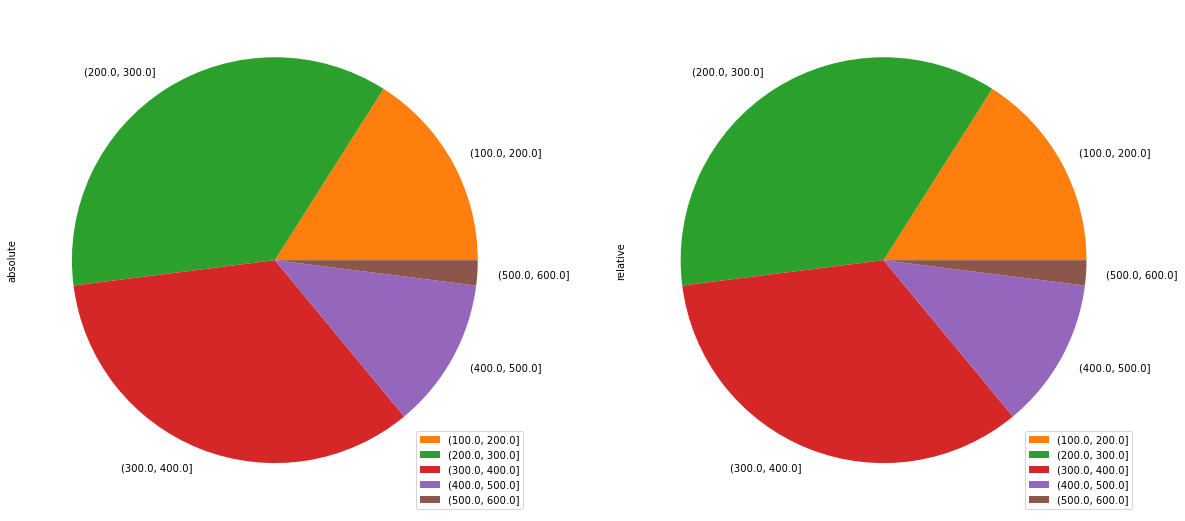

In [12]:
df.plot(kind="pie", subplots = True, figsize=(20,10))

Folie 49: Histogramme

array([[<AxesSubplot:title={'center':'0'}>]], dtype=object)

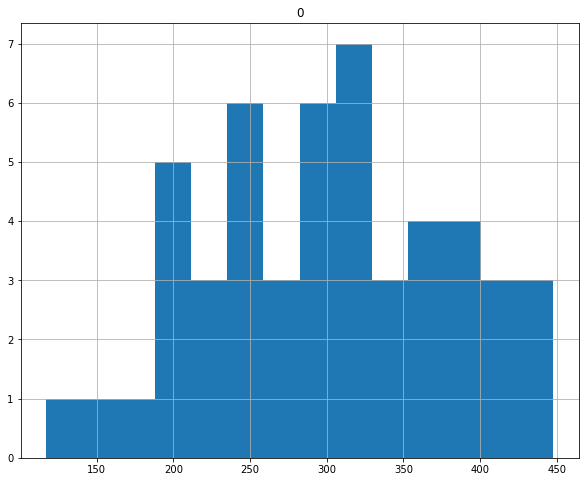

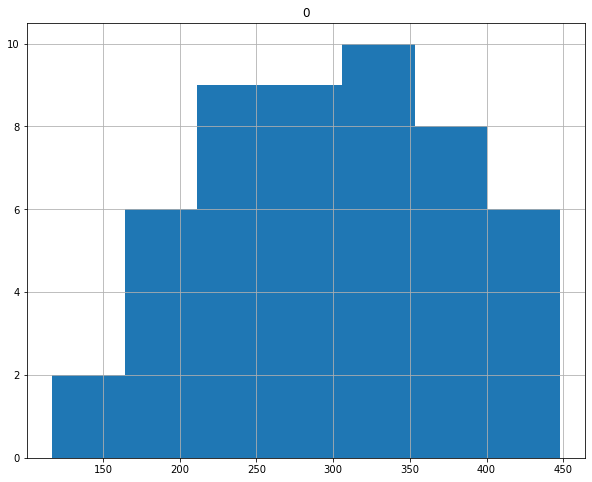

In [14]:
df = pd.DataFrame(np.random.normal(300,75,n))
df.hist(bins= int(2*np.sqrt(n)))
df.hist(bins= int(np.sqrt(n)))

Folie 52: Empirische Verteilungsfunktion

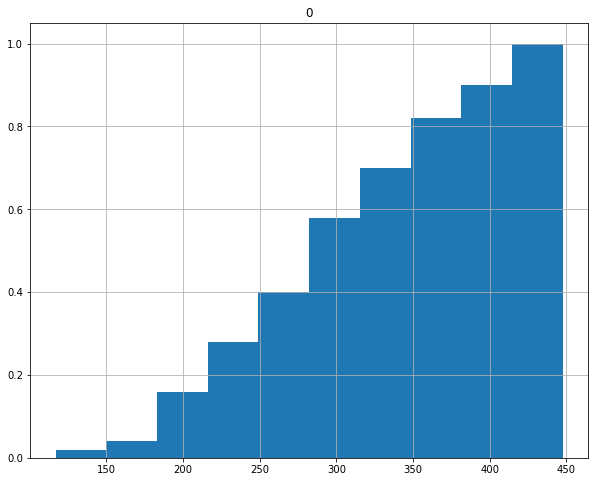

In [15]:
a = df.hist(cumulative = True,bins= int(2*np.sqrt(26)),  density=True)

Folie 54: Arithmetisches Mittel

In [16]:
print(df[0].mean())
df.loc[len(df[0])]=[10000]
print(sum(df[0])/len(df[0]))

300.73808433611674
490.91969052560466


Folie 56: Median

In [18]:
df = pd.DataFrame(np.random.randint(50,600,26))
print("Median: {}".format(df[0].median()))
print("Mean: {}".format(df[0].mean()))
df.loc[len(df[0])]=[10000]
print("Median: {}".format(df[0].median()))
print("Mean: {}".format(df[0].mean()))

Median: 358.5
Mean: 354.3076923076923
Median: 367.0
Mean: 711.5555555555555


Folie 57

Modus: 0    46
dtype: int32


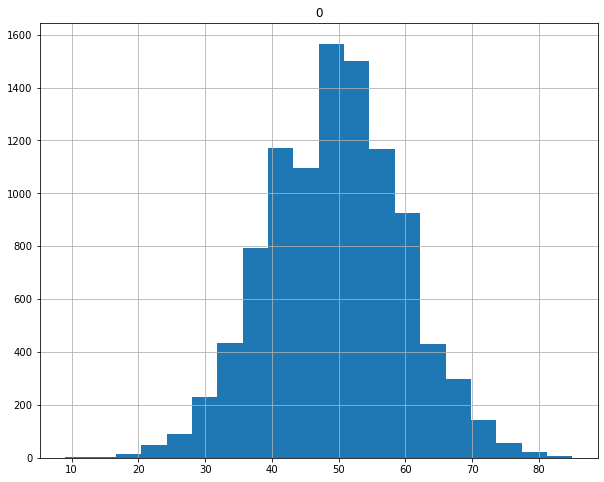

In [40]:
df = pd.DataFrame(np.random.normal(50,10,10000)).astype(int)
df.hist(bins= 20)
print(f"Modus: {df[0].mode()}")

Folie 60: Aufgabe: Lagemaße

mean 0    1.181818
dtype: float64
median 0    1.0
dtype: float64
mode    0
0  0


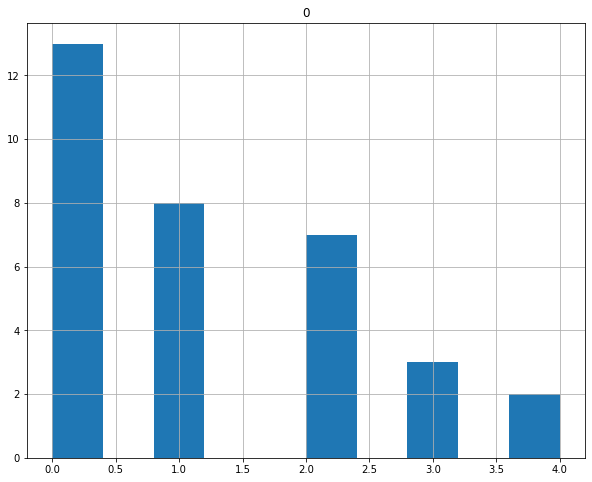

In [41]:
linkssteil = pd.DataFrame((0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,2,2,2,2,2,2,2,3,3,3,4,4))
linkssteil.hist()
print("mean",linkssteil.mean())
print("median",linkssteil.median())
print("mode",linkssteil.mode())
    

Folie 62

In [42]:
df.quantile(0.5)==df.median()

0    True
dtype: bool

In [44]:
from scipy import stats
stats.percentileofscore(df,50)/100

0.5251

Folie 66

<AxesSubplot:>

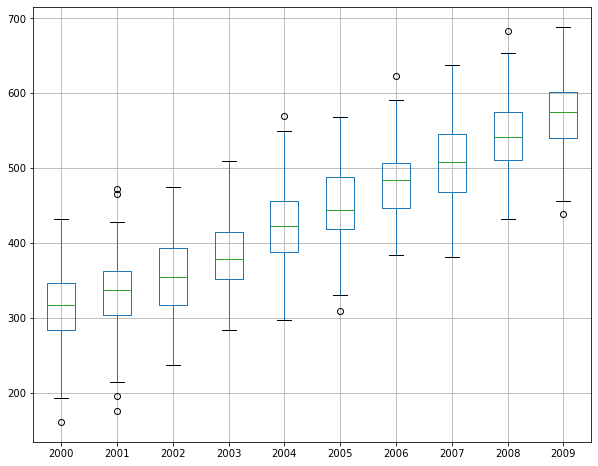

In [45]:
df = pd.DataFrame()
years = []
for i in range(10):
    df[i] = pd.Series(np.random.normal((1+i/10)*300,50, size = 100))
    years.append("200"+str(i))
df.columns = years
df.boxplot()

Folie 67: Box-Plot

<AxesSubplot:>

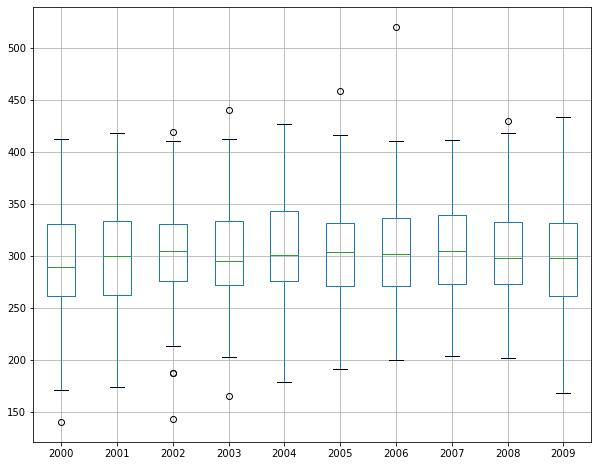

In [46]:
df = pd.DataFrame({y:pd.Series(np.random.normal(300,50, size = 100)) for y in np.arange(2000,2010)})
df.boxplot()

array([[<AxesSubplot:title={'center':'2000'}>,
        <AxesSubplot:title={'center':'2001'}>,
        <AxesSubplot:title={'center':'2002'}>],
       [<AxesSubplot:title={'center':'2003'}>,
        <AxesSubplot:title={'center':'2004'}>,
        <AxesSubplot:title={'center':'2005'}>],
       [<AxesSubplot:title={'center':'2006'}>,
        <AxesSubplot:title={'center':'2007'}>,
        <AxesSubplot:title={'center':'2008'}>],
       [<AxesSubplot:title={'center':'2009'}>, <AxesSubplot:>,
        <AxesSubplot:>]], dtype=object)

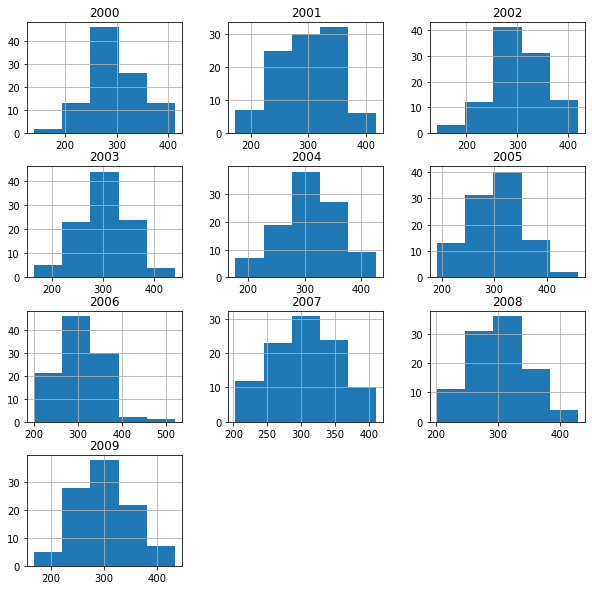

In [47]:
df.hist(bins= int(np.sqrt(26)), figsize =(10,10))

Folie 77: Lorenz-Kurve

In [48]:
from matplotlib import pyplot as plt
def lorenz_curve(X):
    #X=np.append(X,[0])
    X.sort()
    Y_lorenz = X.cumsum() / X.sum()
    X_lorenz = np.arange(Y_lorenz.size)/(Y_lorenz.size-1)
    plt.plot(X_lorenz,Y_lorenz)
    Y = X_lorenz
    plt.fill_between(X_lorenz, Y_lorenz, Y, alpha = 0.1)
    plt.plot(X_lorenz, X_lorenz)

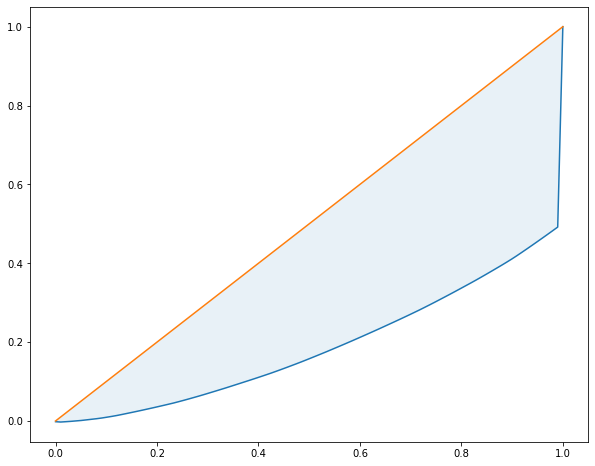

In [49]:
a = np.random.normal(100,50,100)
a[99] = 10000
lorenz_curve(a)

Folie 87: Normalverteilung

<AxesSubplot:ylabel='Frequency'>

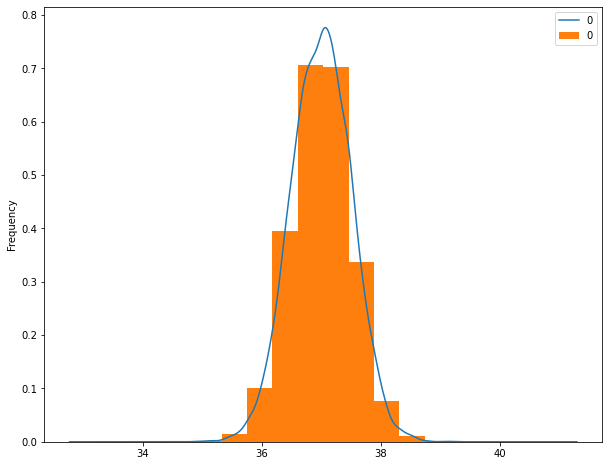

In [57]:
df = pd.DataFrame(np.random.normal(37,0.5,10000))
ax = df.plot(kind="kde")
df.plot(ax=ax,kind="hist", density=True)

Folie 89

((array([-2.46203784, -2.12570747, -1.93122778, -1.79044653, -1.67819304,
         -1.58381122, -1.50174123, -1.42869743, -1.36256869, -1.30191411,
         -1.24570419, -1.19317644, -1.14374949, -1.09696931, -1.05247413,
         -1.00997067, -0.96921765, -0.93001393, -0.89218993, -0.85560121,
         -0.82012357, -0.78564937, -0.75208458, -0.71934648, -0.68736185,
         -0.65606548, -0.62539893, -0.59530962, -0.56574992, -0.53667655,
         -0.50804994, -0.47983378, -0.45199463, -0.42450149, -0.39732558,
         -0.37044003, -0.34381966, -0.31744076, -0.29128096, -0.26531902,
         -0.23953472, -0.21390872, -0.18842244, -0.16305799, -0.13779803,
         -0.1126257 , -0.08752455, -0.06247843, -0.03747145, -0.01248789,
          0.01248789,  0.03747145,  0.06247843,  0.08752455,  0.1126257 ,
          0.13779803,  0.16305799,  0.18842244,  0.21390872,  0.23953472,
          0.26531902,  0.29128096,  0.31744076,  0.34381966,  0.37044003,
          0.39732558,  0.42450149,  0.

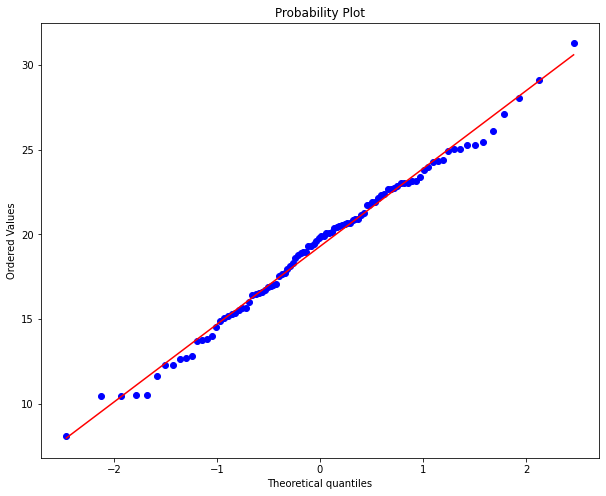

In [65]:
import scipy.stats as stats
import matplotlib.pyplot as plt

df = pd.DataFrame(np.random.normal(loc = 20, scale = 5, size=100))
stats.probplot(df[0], dist="norm", plot=plt)

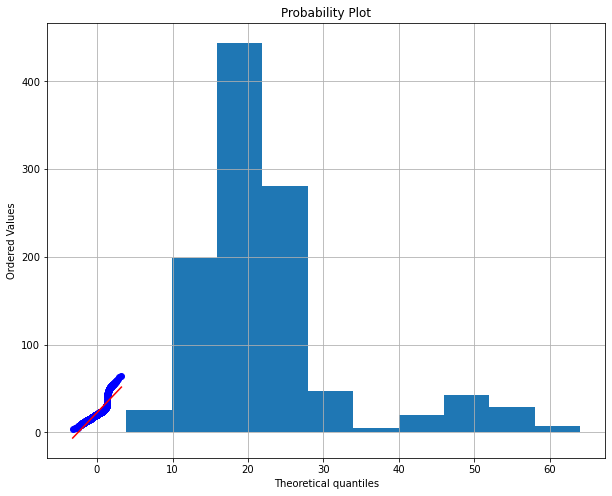

In [69]:
measurements = np.random.normal(loc = 20, scale = 5, size=1000)
measurements = np.append(measurements,np.random.normal(loc = 50, scale = 5, size=100))
serie = pd.Series(measurements)
serie.hist()
stats.probplot(serie, dist="norm", plot=plt)
plt.show()

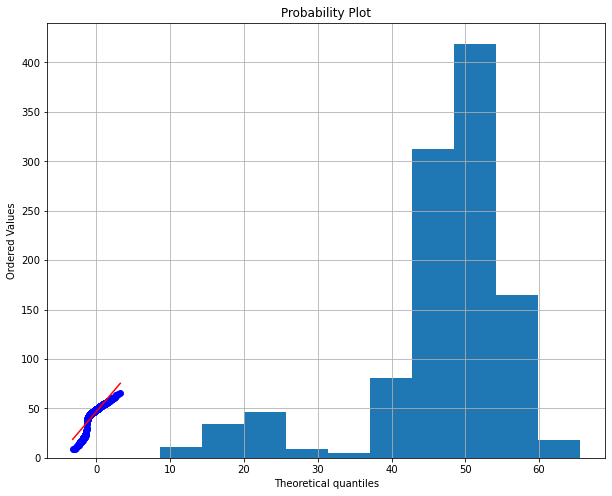

In [70]:
measurements = np.random.normal(loc = 20, scale = 5, size=100)
measurements = np.append(measurements,np.random.normal(loc = 50, scale = 5, size=1000))
serie = pd.Series(measurements)
serie.hist()
stats.probplot(serie, dist="norm", plot=plt)
plt.show()

In [71]:
from scipy.stats import norm, shapiro
my_data = norm.rvs(size=500)
print(stats.shapiro(my_data))
my_data = np.random.randint(0,100,500)
print(stats.shapiro(my_data))
# if p-value <0.05 no normal distribution

ShapiroResult(statistic=0.9978616237640381, pvalue=0.7857986092567444)
ShapiroResult(statistic=0.9573103189468384, pvalue=7.51899931206168e-11)


Folie 92

In [72]:
#kerndichteschätzer
def kernel_density_estimator(x, data, kernel, h):
    y = 0 
    for x_i in data:
        y += 1/h*kernel((x-x_i)/h)
    return y/len(data)

def rect_kernel(u):
    return 1/2 if -1<=u<1 else 0

def gaussian_kernel(u):
    return 1/(2*np.pi)*np.e**(-1/2*u**2)

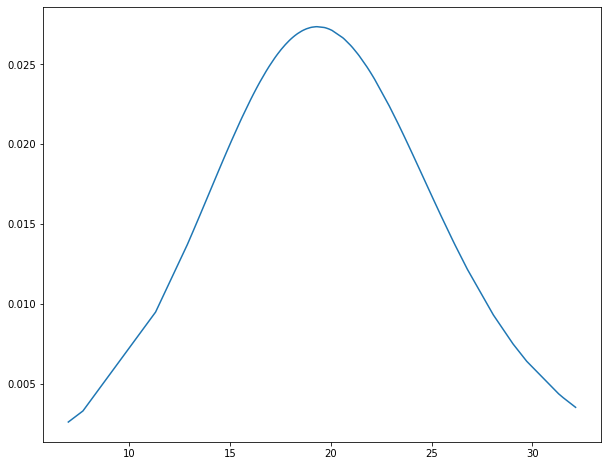

In [73]:
data = np.random.normal(loc = 20, scale = 5, size=100)
data = np.sort(data)
y = np.zeros(len(data))
for i,x in enumerate(data):
    y[i] = kernel_density_estimator(x, data, gaussian_kernel, 4)
plt.plot(data,y)

Folie 93

In [74]:
from matplotlib.gridspec import GridSpec
def plot_kde_approx(data):
    fig = plt.figure(figsize=(5,5))
    gs = GridSpec(1,1)
    a1 = fig.add_subplot(gs[0,0])
    xmin, xmax = min(data),max(data)
    positions = np.linspace(xmin, xmax, len(data))
    kde = stats.gaussian_kde(data)
    pd.Series(data).hist(ax= a1, bins = int(2*np.sqrt(len(data))), density=1)
    a1.plot(positions,kde(positions))
    plt.show()

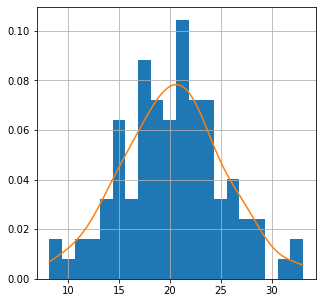

In [75]:
data = np.random.normal(loc = 20, scale = 5, size=100)
plot_kde_approx(data)

Folie 94

In [76]:
from matplotlib.gridspec import GridSpec
from sklearn.neighbors import KernelDensity

def plot_kde_approx(data, kernel, ax):
    pd.Series(data).hist(ax= ax, bins = int(2*np.sqrt(len(data))), density=1)
    xmin, xmax = min(data),max(data)  
    positions = np.linspace(xmin, xmax, len(data))[:, np.newaxis]
    kde = KernelDensity(kernel=kernel)
    kde.fit(data.reshape(-1, 1))    
    log_dens = kde.score_samples(positions)
    ax.plot(positions[:, 0],  np.exp(log_dens))

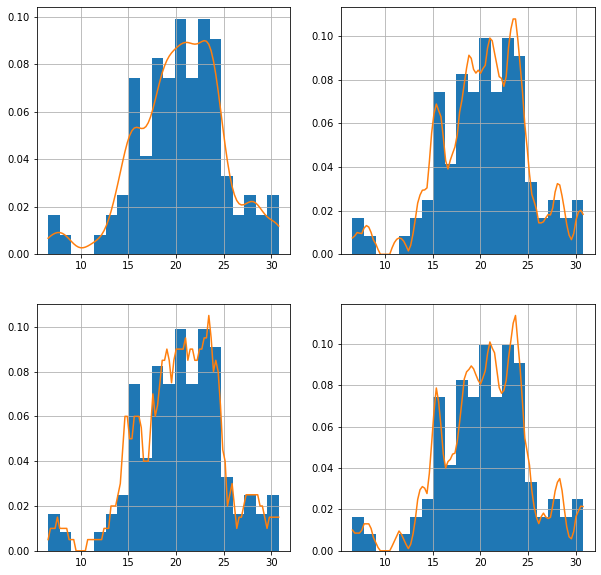

In [77]:
fig = plt.figure(figsize=(10,10))
gs = GridSpec(2,2)
a1 = fig.add_subplot(gs[0,0])
a2 = fig.add_subplot(gs[1,0])
a3 = fig.add_subplot(gs[0,1])
a4 = fig.add_subplot(gs[1,1])

data = np.random.normal(loc = 20, scale = 5, size=100)
plot_kde_approx(data, "gaussian", a1)
plot_kde_approx(data, "tophat", a2)
plot_kde_approx(data, "epanechnikov", a3)
plot_kde_approx(data, "linear", a4)
plt.show()